# VisionMatch AI — 03. Retrieval Evaluation

**Mục đích:** kiểm tra hệ thống tìm kiếm ảnh tương tự bằng CLIP hoạt động ra sao với (1) ảnh nằm trong catalog và (2) ảnh mới bên ngoài catalog. Không chỉ xem điểm số: notebook còn **hiển thị ảnh query và Top-K ảnh tìm được** để nhận xét bằng mắt.

**Nguồn:** [Cleanlab/footwear-demo (Hugging Face)](https://huggingface.co/datasets/Cleanlab/footwear-demo). Các file được tạo bởi `scripts/download_dataset.py`, `scripts/prepare_dataset.py`, `scripts/build_index.py`; thuật toán CLI nằm ở `scripts/search.py`.

**Dữ liệu đầu vào:** `data/processed/catalog.csv`, `artifacts/clip_embeddings.npy`, ảnh trong `data/raw/test-zip/` và ảnh bên ngoài `data/queries/query_shoe.jpg` (nếu có).

**Kết quả những lần chạy trước (chưa phải kết quả chạy notebook):** index có 909 ảnh, vector 512 chiều. Truy vấn `boot/00980.jpg`: 5/5 cùng nhãn (K=5); `sandal/004e3.jpg`: 6/6 (K=6); `shoe/02647.jpg`: 5/6 (K=6). Với `query_shoe.jpg` bên ngoài: top 5 gồm sandal, boot, shoe, shoe, boot; điểm khoảng 0.7065–0.7267. Notebook sẽ **tự tính lại** từ dữ liệu trên máy.

> **Lưu ý:** “cùng category” chỉ là một thước đo proxy dựa trên nhãn thư mục, không tương đương “giống nhau về ngoại hình”; không gọi đó là accuracy hay Recall@K. Notebook này không sửa catalog, ảnh hoặc embeddings.

## 0. Quy trình retrieval và cách chạy

**Ảnh trong catalog:** dùng embedding đã lưu ở đúng hàng CSV → nhân ma trận để tính cosine similarity → loại chính ảnh query → sắp xếp Top-K.

**Ảnh ngoài catalog:** mở ảnh mới → dùng đúng CLIP `openai/clip-vit-base-patch32` và processor như khi build index → L2 normalization → tìm Top-K trong 909 vector đã lưu.

**Điều kiện trước khi chạy:** đã thực hiện `python scripts/prepare_dataset.py` và `python scripts/build_index.py`. Chọn kernel `.venv` trong VS Code; nếu thiếu package, cài từ terminal: `python -m pip install numpy pandas pillow matplotlib torch transformers`. Chạy từng cell từ trên xuống hoặc **Run All**.

**Quan trọng:** thứ tự hàng `catalog.csv` phải trùng với hàng `clip_embeddings.npy`. Nếu CSV đổi sau khi build, cần build lại index.

## 1. Load index — nạp metadata và vector

**Mục đích:** đọc hai file kết quả pipeline; kiểm tra chúng khớp nhau và mỗi vector có 512 chiều, không chứa NaN/Inf, chuẩn hóa L2. **Đầu ra cần thấy:** `909` records, shape `(909, 512)` (nếu dữ liệu chưa thay đổi), norms gần `1.0`.

**Giới hạn:** shape bằng nhau chưa chứng minh tuyệt đối thứ tự ảnh–vector khớp; notebook giả định cả hai được tạo từ cùng lần build.

In [21]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# VS Code thường chạy notebook tại thư mục project hoặc notebooks/.
def find_project_root():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "scripts" / "build_index.py").is_file():
            return folder
    raise FileNotFoundError("Không tìm thấy project visionmatch-ai; hãy mở notebook trong VS Code tại project.")

ROOT = find_project_root()
CATALOG_PATH = ROOT / "data/processed/catalog.csv"
EMBEDDINGS_PATH = ROOT / "artifacts/clip_embeddings.npy"

catalog = pd.read_csv(CATALOG_PATH)
embeddings = np.load(EMBEDDINGS_PATH, allow_pickle=False)
assert {"image_path", "category"}.issubset(catalog.columns), "Catalog thiếu cột cần thiết"
assert embeddings.ndim == 2 and embeddings.shape[0] == len(catalog), "Index và catalog không khớp"
assert embeddings.shape[1] == 512, "Số chiều không đúng với CLIP ViT-B/32"
assert np.isfinite(embeddings).all(), "Có NaN/Inf trong embeddings"
norms = np.linalg.norm(embeddings, axis=1)
assert np.allclose(norms, 1, atol=1e-4), "Index chưa L2 normalized"
print("Project:", ROOT)
print("Catalog records:", len(catalog))
print("Embedding shape:", embeddings.shape)
print("Embedding dtype:", embeddings.dtype)
print("L2 norm range:", (float(norms.min()), float(norms.max())))
display(catalog.head(3))

Project: d:\SGU(1)\official\visionmatch-ai
Catalog records: 909
Embedding shape: (909, 512)
Embedding dtype: float32
L2 norm range: (0.9999998807907104, 1.0000001192092896)


,image_id,image_path,category,width,height
0,0,data/raw/test-zip/boot/00980.jpg,boot,136,102
1,1,data/raw/test-zip/boot/00d04.jpg,boot,136,102
2,2,data/raw/test-zip/boot/01a4f.jpg,boot,136,102


## 2. Hàm tìm kiếm và hiển thị ảnh

**Mục đích:** viết các hàm dùng lại cho nhiều truy vấn. Đặt code chung một chỗ để các cell thử nghiệm dễ đọc.

- `rank_top_k`: cosine similarity = tích vô hướng vì embeddings đã chuẩn hóa; loại chính ảnh truy vấn nếu biết index.
- `show_results`: vẽ **query bên trái, kết quả Top-K bên phải**, ghi nhãn và score.
- Điểm cosine **không phải phần trăm xác suất**. Hai ảnh có thể cùng category nhưng ngoại hình rất khác nhau.

**Kiểm soát:** trả đúng K (hoặc ít hơn nếu catalog quá nhỏ); thứ tự score giảm dần.

In [22]:
def rank_top_k(query_vector, k=5, exclude_index=None):
    if k < 1:
        raise ValueError("k phải >= 1")
    query_vector = np.asarray(query_vector, dtype=np.float32)
    assert query_vector.shape == (embeddings.shape[1],), "Sai số chiều query"
    assert np.isfinite(query_vector).all(), "Query chứa NaN/Inf"
    query_vector = query_vector / np.linalg.norm(query_vector)
    scores = embeddings @ query_vector
    if exclude_index is not None:
        scores[int(exclude_index)] = -np.inf
    valid = np.isfinite(scores)
    indices = np.flatnonzero(valid)
    ranked = indices[np.argsort(scores[indices])[::-1][:k]]
    results = catalog.iloc[ranked][["image_path", "category"]].copy()
    results.insert(0, "rank", np.arange(1, len(ranked) + 1))
    results["cosine_similarity"] = scores[ranked]
    return results.reset_index(drop=True)


def show_results(query_path, results, query_label="External query"):
    query_path = Path(query_path)
    count = len(results) + 1
    fig, axes = plt.subplots(1, count, figsize=(3.1 * count, 3.7), squeeze=False)
    for j, ax in enumerate(axes[0]):
        ax.axis("off")
        if j == 0:
            path = query_path
            title = f"QUERY\n{query_label}"
        else:
            row = results.iloc[j-1]
            path = ROOT / row["image_path"]
            title = f"#{j} {row['category']}\nscore={row['cosine_similarity']:.4f}"
        if path.is_file():
            with Image.open(path) as img:
                ax.imshow(img.convert("RGB"))
        else:
            ax.text(0.5, 0.5, f"Missing file:\n{path.name}", ha="center", va="center")
        ax.set_title(title, fontsize=10)
    plt.tight_layout()
    plt.show()


def find_catalog_index(relative_path):
    normalized = Path(relative_path).as_posix()
    hits = np.flatnonzero((catalog["image_path"] == normalized).to_numpy())
    if len(hits) != 1:
        raise ValueError(f"Expected exactly 1 catalog match for {normalized}, found {len(hits)}")
    return int(hits[0])

## 3. In-dataset queries — test boot / sandal / shoe

**Mục đích:** tái hiện 3 truy vấn CLI đã chạy và nhìn ảnh trả về bằng mắt.

**Cách đọc bảng:** `same_category_in_top_k` = số ảnh cùng nhãn query trong Top-K. Đây là **category-match@K trên những truy vấn đang thử**, không phải đánh giá chất lượng tổng quát trên toàn dataset.

**Lưu ý kiểm thử:** query đã nằm trong index, nên **phải loại chính nó**. Ở cell này dùng embedding có sẵn của query nhằm kiểm tra retrieval/index nhanh; không chạy lại image encoder (khác với CLI, nhưng về lý thuyết phải rất gần nếu preprocessing nhất quán).


Query: data/raw/test-zip/boot/00980.jpg | same category: 5/5


,rank,image_path,category,cosine_similarity
0,1,data/raw/test-zip/boot/c8220.jpg,boot,0.955574
1,2,data/raw/test-zip/boot/ed41d.jpg,boot,0.955208
2,3,data/raw/test-zip/boot/178a0.jpg,boot,0.950270
3,4,data/raw/test-zip/boot/77163.jpg,boot,0.949800
4,5,data/raw/test-zip/boot/8448c.jpg,boot,0.947974


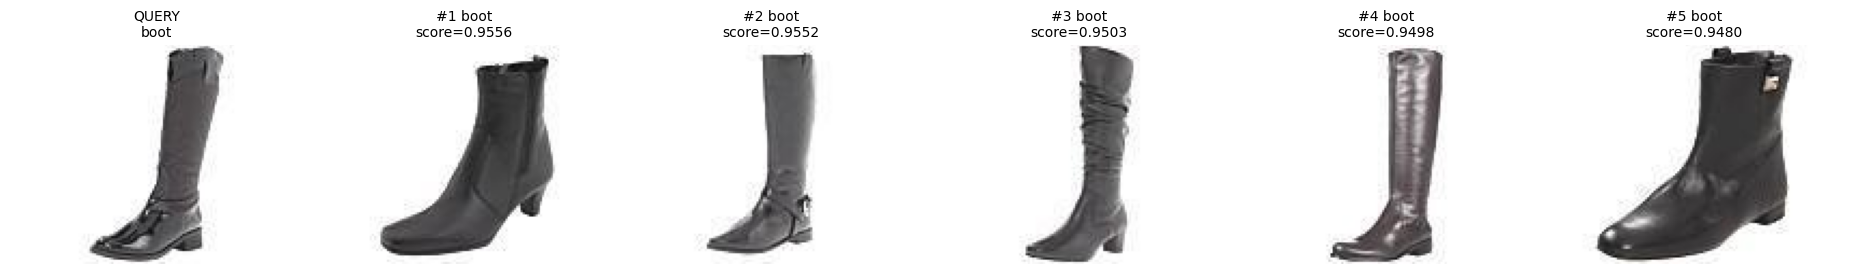


Query: data/raw/test-zip/sandal/004e3.jpg | same category: 6/6


,rank,image_path,category,cosine_similarity
0,1,data/raw/test-zip/sandal/a8be7.jpg,sandal,0.936034
1,2,data/raw/test-zip/sandal/bc028.jpg,sandal,0.930461
2,3,data/raw/test-zip/sandal/efe07.jpg,sandal,0.929847
3,4,data/raw/test-zip/sandal/43c03.jpg,sandal,0.928755
4,5,data/raw/test-zip/sandal/e9106.jpg,sandal,0.928656
5,6,data/raw/test-zip/sandal/ceadf.jpg,sandal,0.927466


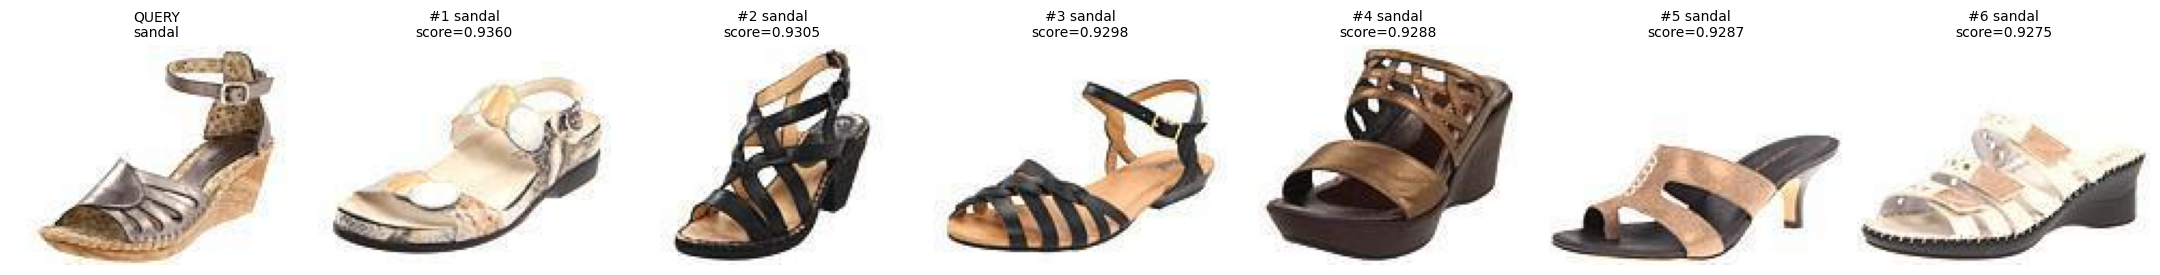


Query: data/raw/test-zip/shoe/02647.jpg | same category: 5/6


,rank,image_path,category,cosine_similarity
0,1,data/raw/test-zip/shoe/2209d.jpg,shoe,0.942290
1,2,data/raw/test-zip/shoe/593b3.jpg,shoe,0.938138
2,3,data/raw/test-zip/shoe/f0930.jpg,shoe,0.937052
3,4,data/raw/test-zip/shoe/0d9cc.jpg,shoe,0.933178
4,5,data/raw/test-zip/shoe/7885c.jpg,shoe,0.933089
5,6,data/raw/test-zip/boot/6733e.jpg,boot,0.931831


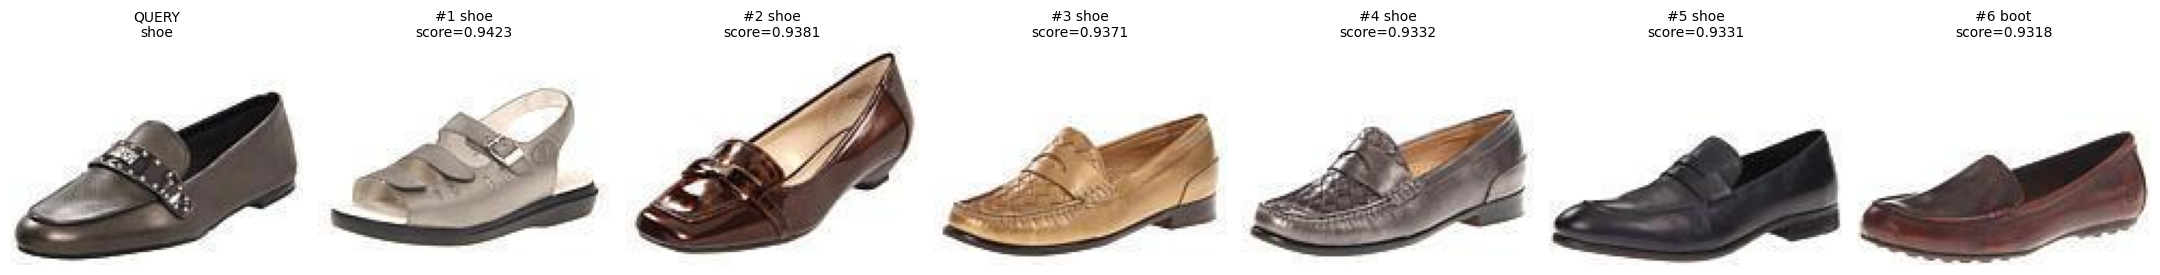

SUMMARY — chỉ cho các query đã chọn


,query,category,K,same_category_in_top_k,category_match_fraction
0,data/raw/test-zip/boot/00980.jpg,boot,5,5,1.000000
1,data/raw/test-zip/sandal/004e3.jpg,sandal,6,6,1.000000
2,data/raw/test-zip/shoe/02647.jpg,shoe,6,5,0.833333


In [23]:
CASES = [
    ("data/raw/test-zip/boot/00980.jpg", 5),
    ("data/raw/test-zip/sandal/004e3.jpg", 6),
    ("data/raw/test-zip/shoe/02647.jpg", 6),
]

case_results = {}
summary = []
for relative_path, k in CASES:
    query_index = find_catalog_index(relative_path)
    query_category = str(catalog.iloc[query_index]["category"])
    results = rank_top_k(embeddings[query_index], k=k, exclude_index=query_index)
    same = int(results["category"].eq(query_category).sum())
    summary.append({"query": relative_path, "category": query_category, "K": k,
                    "same_category_in_top_k": same, "category_match_fraction": same / len(results)})
    case_results[relative_path] = results
    print(f"\nQuery: {relative_path} | same category: {same}/{len(results)}")
    display(results)
    show_results(ROOT / relative_path, results, query_label=query_category)

summary_df = pd.DataFrame(summary)
print("SUMMARY — chỉ cho các query đã chọn")
display(summary_df)

## 4. External query — ảnh nằm ngoài catalog

**Mục đích:** thử đúng tình huống người dùng tải ảnh mới lên hệ thống. Ảnh mẫu: `data/queries/query_shoe.jpg` (theo lần test bạn đã thực hiện).

**Tại sao phải encode lại?** Ảnh này không có vector sẵn trong `clip_embeddings.npy`; cần mở ảnh rồi chạy CLIP Image Encoder và chuẩn hóa L2. Cell dưới **chỉ load CLIP lúc thực sự có ảnh query**, không tạo hay lưu index mới.

**Đầu ra cần kiểm tra:** in `Query embedding shape: (512,)`, bảng Top-5, và hình query + 5 ảnh giống nhất. **Không áp dụng tỷ lệ cùng category** nếu ảnh mới chưa có ground-truth đáng tin cậy.

**Lưu ý:** Query chụp ngoài trời có nền, người và quần; khác biệt so với ảnh catalog có thể ảnh hưởng xếp hạng. Nếu file chưa tồn tại, cell sẽ thông báo và bỏ qua phần này.

### Cấu hình và tìm các ảnh bên ngoài dataset

Mục đích: Tự động lấy tất cả ảnh .jpg, .jpeg, .png, .webp trong data/queries/.

In [24]:

from pathlib import Path

QUERY_DIR = ROOT / "data/queries"
EXTERNAL_K = 5
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

QUERY_DIR.mkdir(parents=True, exist_ok=True)

external_images = sorted(
    path
    for path in QUERY_DIR.iterdir()
    if path.is_file()
    and path.suffix.lower() in IMAGE_EXTENSIONS
)

print(f"Found external query images: {len(external_images)}")

for index, image_path in enumerate(external_images, start=1):
    print(f"{index}. {image_path.name}")

if not external_images:
    print("Hãy thêm ảnh vào data/queries/ rồi chạy lại cell.")


Found external query images: 5
1. loafer_brown.png
2. query_boot.png
3. query_sandal.png
4. query_shoe.jpg
5. sneaker_white.png


### Load CLIP một lần và tạo hàm encode ảnh

Mục đích: Tách việc encode ảnh thành một hàm có thể tái sử dụng cho tất cả query.

In [25]:

import numpy as np
import torch
from PIL import Image
from transformers import AutoProcessor, CLIPModel

MODEL_ID = "openai/clip-vit-base-patch32"

device = "cuda" if torch.cuda.is_available() else "cpu"

processor = AutoProcessor.from_pretrained(MODEL_ID)
model = CLIPModel.from_pretrained(MODEL_ID).to(device).eval()

print("Model:", MODEL_ID)
print("Device:", device)


def encode_external_image(image_path):
    """Encode an image using pretrained CLIP."""

    with Image.open(image_path) as img:
        rgb_image = img.convert("RGB")

    inputs = processor(
        images=rgb_image,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.inference_mode():
        features = model.get_image_features(**inputs)

        if not isinstance(features, torch.Tensor):
            features = features.pooler_output

        features = torch.nn.functional.normalize(
            features, p=2, dim=-1
        )

    query_vector = features.cpu().numpy()[0]

    return query_vector


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Model: openai/clip-vit-base-patch32
Device: cpu


### Tìm Top-5 và trực quan hóa cho tất cả ảnh

Mục đích: Lặp qua các ảnh trong data/queries/, tạo embedding, tìm Top-K và hiển thị kết quả tương ứng.

Cell này tái sử dụng hai hàm có sẵn trong notebook 03: rank_top_k() và show_results().

[1/5] Query: loafer_brown.png


,rank,image_path,category,cosine_similarity
0,1,data/raw/test-zip/shoe/b9638.jpg,shoe,0.878141
1,2,data/raw/test-zip/shoe/23d98.jpg,shoe,0.866218
2,3,data/raw/test-zip/sandal/aa3ed.jpg,sandal,0.863715
3,4,data/raw/test-zip/boot/e2fe2.jpg,boot,0.862597
4,5,data/raw/test-zip/shoe/fbd44.jpg,shoe,0.862577


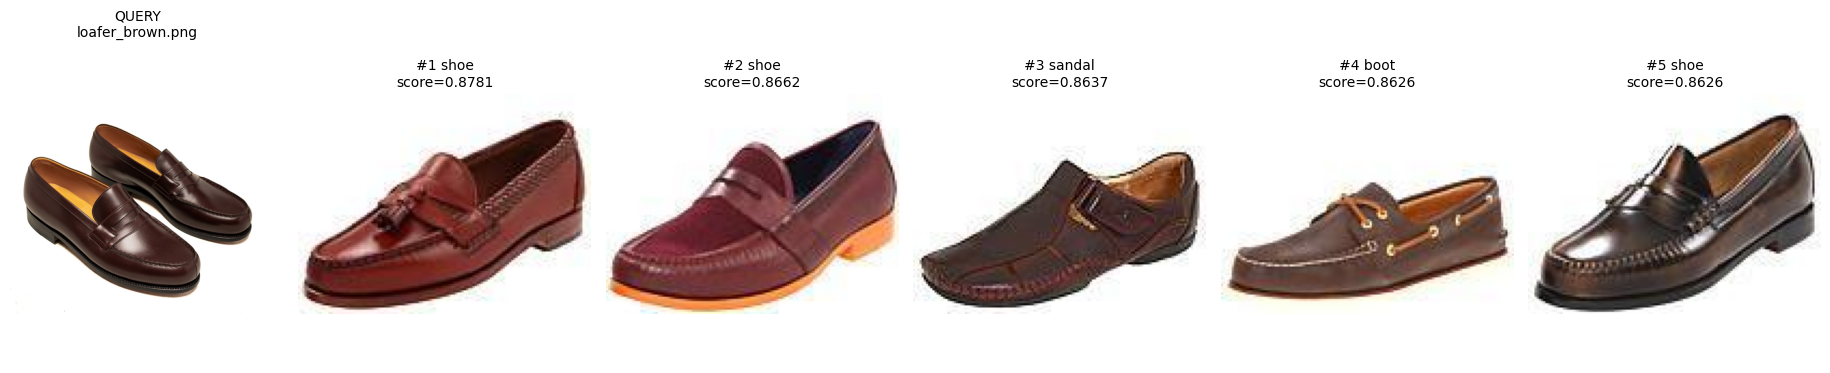

[2/5] Query: query_boot.png


,rank,image_path,category,cosine_similarity
0,1,data/raw/test-zip/boot/468e1.jpg,boot,0.773650
1,2,data/raw/test-zip/boot/989a5.jpg,boot,0.747663
2,3,data/raw/test-zip/boot/31e09.jpg,boot,0.745676
3,4,data/raw/test-zip/boot/87478.jpg,boot,0.743540
4,5,data/raw/test-zip/shoe/20275.jpg,shoe,0.735607


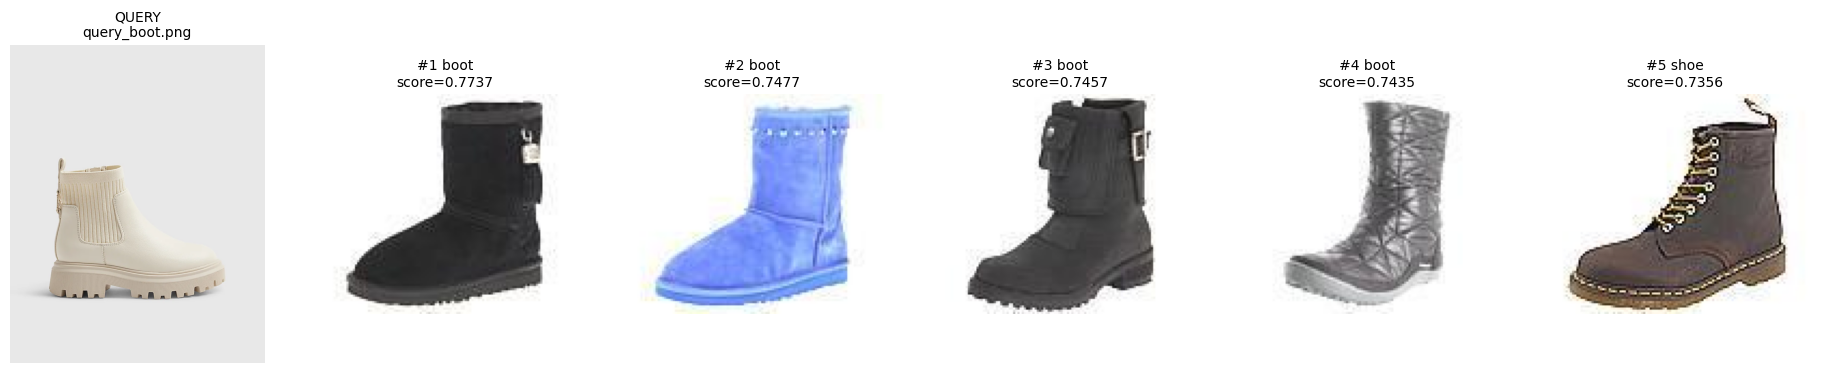

[3/5] Query: query_sandal.png


,rank,image_path,category,cosine_similarity
0,1,data/raw/test-zip/sandal/ee640.jpg,sandal,0.802024
1,2,data/raw/test-zip/sandal/84911.jpg,sandal,0.797840
2,3,data/raw/test-zip/shoe/1c62b.jpg,shoe,0.797412
3,4,data/raw/test-zip/boot/6fdd1.jpg,boot,0.797094
4,5,data/raw/test-zip/shoe/5f63e.jpg,shoe,0.797070


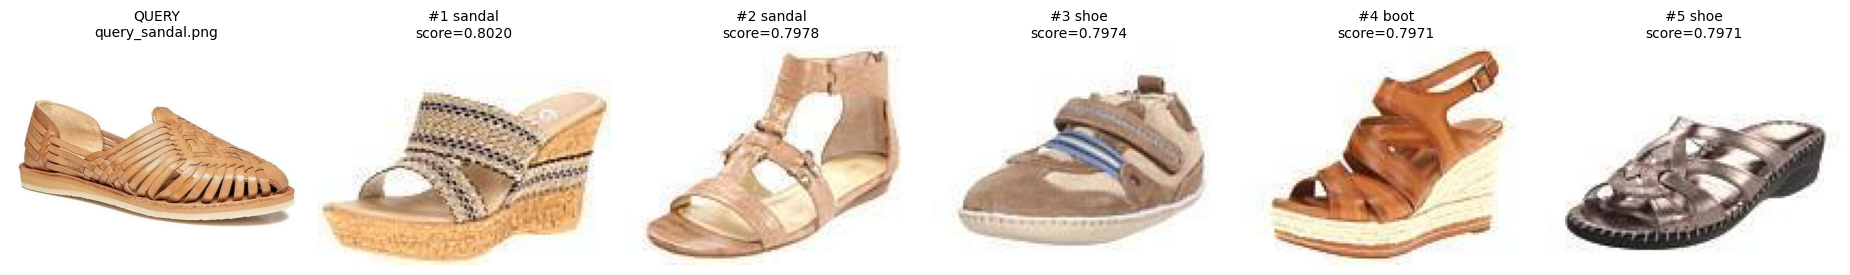

[4/5] Query: query_shoe.jpg


,rank,image_path,category,cosine_similarity
0,1,data/raw/test-zip/sandal/9a219.jpg,sandal,0.726748
1,2,data/raw/test-zip/boot/c9e4c.jpg,boot,0.719732
2,3,data/raw/test-zip/shoe/72624.jpg,shoe,0.715282
3,4,data/raw/test-zip/shoe/1c62b.jpg,shoe,0.711517
4,5,data/raw/test-zip/boot/05fd5.jpg,boot,0.706508


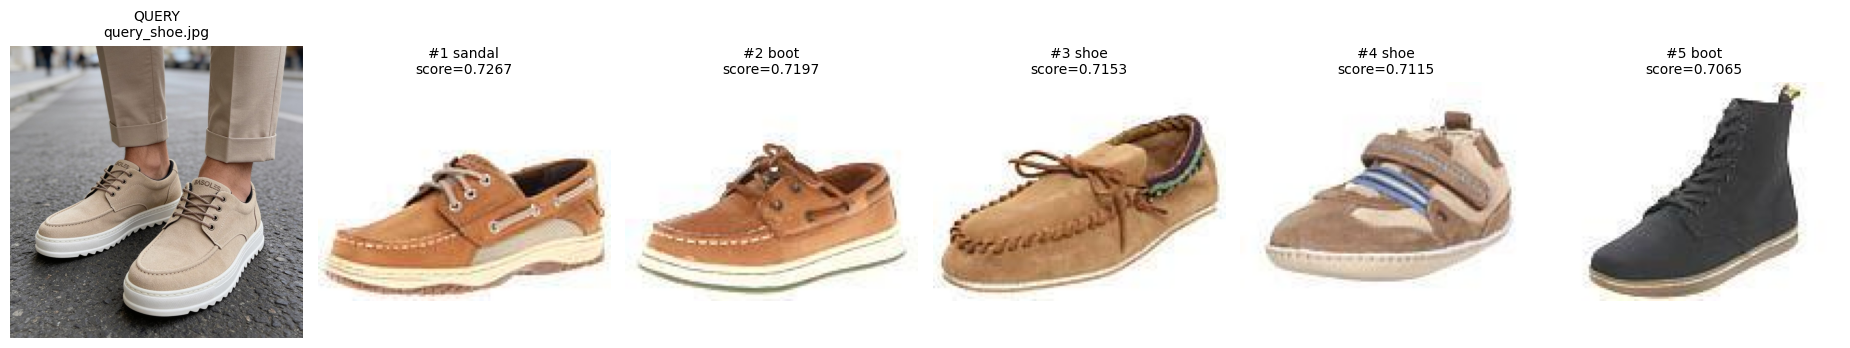

[5/5] Query: sneaker_white.png


,rank,image_path,category,cosine_similarity
0,1,data/raw/test-zip/shoe/cf322.jpg,shoe,0.783658
1,2,data/raw/test-zip/shoe/1c62b.jpg,shoe,0.757539
2,3,data/raw/test-zip/shoe/af65b.jpg,shoe,0.746943
3,4,data/raw/test-zip/sandal/a514f.jpg,sandal,0.744143
4,5,data/raw/test-zip/shoe/bd481.jpg,shoe,0.743041


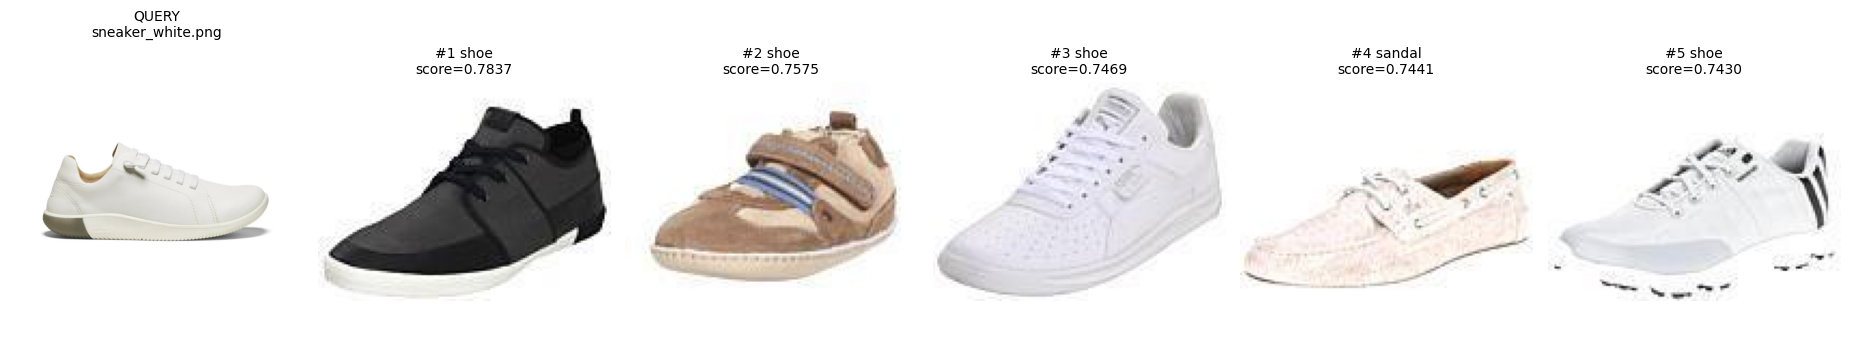


External Query Evaluation Completed!
Successful queries: 5
Failed queries: 0


In [26]:

# Lưu kết quả để có thể phân tích lại sau
external_results_all = {}
failed_queries = {}

for index, image_path in enumerate(external_images, start=1):

    print("=" * 70)
    print(f"[{index}/{len(external_images)}] Query: {image_path.name}")

    try:
        # 1. Encode ảnh query thành vector 512 chiều
        query_vector = encode_external_image(image_path)

        # 2. Kiểm tra embedding
        assert np.isfinite(query_vector).all()
        assert np.isclose(
            np.linalg.norm(query_vector), 1.0, atol=1e-4
        )

        # 3. Tìm Top-K ảnh tương tự
        results = rank_top_k(
            query_vector,
            k=EXTERNAL_K
        )

        # 4. Lưu kết quả vào dictionary
        external_results_all[image_path.name] = results

        # 5. Hiển thị bảng kết quả
        display(results)

        # 6. Hiển thị ảnh query và các ảnh Top-K
        show_results(
            image_path,
            results,
            query_label=image_path.name
        )

    except (OSError, ValueError, RuntimeError) as error:
        failed_queries[image_path.name] = str(error)
        print(f"Error: {error}")

print("\n" + "=" * 70)
print("External Query Evaluation Completed!")
print("Successful queries:", len(external_results_all))
print("Failed queries:", len(failed_queries))

if failed_queries:
    print("Failed files:", failed_queries)


## 5. So sánh với kết quả CLI & nhận xét định tính

**Mục đích:** kiểm tra notebook có nhất quán với những lần chạy `scripts/search.py` trước hay không, rồi rút ra kết luận dựa trên **ảnh thực tế**.

**Log CLI đã ghi nhận:**

| Query | K | Kết quả log cũ |
|---|---:|---|
| boot/00980.jpg | 5 | 5 boot; điểm 0.9480–0.9555 |
| sandal/004e3.jpg | 6 | 6 sandal; điểm 0.9281–0.9349 |
| shoe/02647.jpg | 6 | 5 shoe + 1 boot; điểm 0.9325–0.9423 |
| data/queries/query_shoe.jpg | 5 | sandal, boot, shoe, shoe, boot; điểm 0.7065–0.7267 |

Các giá trị trên là **mốc tham khảo từ terminal**, không phải đầu ra chạy notebook. Có thể có chênh lệch rất nhỏ do cách encode hoặc cấu hình processor; so sánh kết quả thực tế bên trên, không ép khớp tuyệt đối.

**Câu hỏi cần tự trả lời khi xem hình:**
1. Trong từng category, ảnh Top-K giống query về **kiểu dáng**, **màu sắc**, hay chỉ **loại giày**?
2. Vì sao query `shoe/02647.jpg` lại có một kết quả `boot` ở hạng 6? Liệu nó có thực sự giống về ngoại hình?
3. Với ảnh ngoài catalog, kết quả đầu là sandal. Đôi giày sandal đó có thật sự giống ảnh query hay mô hình đang bị ảnh hưởng bởi bối cảnh/góc chụp?
4. Thử thêm ảnh với nền trắng, ảnh chụp ngang và ảnh chụp ngoài trời để nhận diện các tình huống thất bại.

**Chú ý:** Mình không kết luận nguyên nhân hay tính đúng/sai nếu chưa quan sát chính những ảnh kết quả trên máy bạn.

## 6. Findings & Next Steps — ghi lại kết quả nghiên cứu

**Điền nhận xét sau khi Run All** (có thể chỉnh Markdown cell này và lưu notebook):

- **Index health:** số vector / shape / norm / NaN có hợp lệ không?
- **In-dataset:** số ảnh cùng category trong Top-K của boot, sandal, shoe; các ảnh có thật sự tương tự không?
- **External query:** mô hình ưu tiên nhãn và ngoại hình nào? Chất lượng tìm kiếm có đáp ứng mục tiêu người dùng không?
- **Failure cases:** ghi ít nhất 1–2 ví dụ cụ thể gồm tên query, ảnh kết quả, rank và nguyên nhân *giả thuyết* (không khẳng định khi thiếu chứng cứ).

**Giới hạn nghiên cứu:** ba truy vấn trong catalog và một ảnh ngoài catalog là tập mẫu quá nhỏ. `category_match_fraction` chỉ phản ánh nhãn thư mục; chưa phải **Recall@K, mAP@K hoặc độ chính xác tổng quát**. Để đánh giá định lượng, cần nhiều query và định nghĩa/nhãn relevance cho từng query–result.

**Bước sau:** (1) kiểm thử thêm 20–30 truy vấn đa dạng; (2) có thể tạo file kết quả đánh giá riêng khi cần; (3) viết unit tests cho `scripts/search.py`; (4) xây dựng demo Gradio khi retrieval đã ổn định.